In [1]:
import numpy as np  # Librería para cálculo numérico
import pandas as pd  # Librería para manipulación de datos
import matplotlib.pyplot as plt  # Librería para crear gráficos
import os

In [3]:
data = pd.read_csv("recursos_humanos.csv")  # Carga el archivo CSV
data  # Muestra los datos

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [5]:
data.left.value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

In [7]:
data.left.value_counts(normalize=True)*100

left
0    76.191746
1    23.808254
Name: proportion, dtype: float64

In [9]:
# Recodificación de variables categóricas
data = pd.get_dummies(data, columns=['sales', 'salary'])

In [11]:
data = data.astype({col: int for col in data.select_dtypes(include='bool').columns})
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [13]:
# Separación de empleados
S = data[data.left == 1]  # Empleados que se fueron
P = data[data.left == 0]  # Empleados que permanecieron

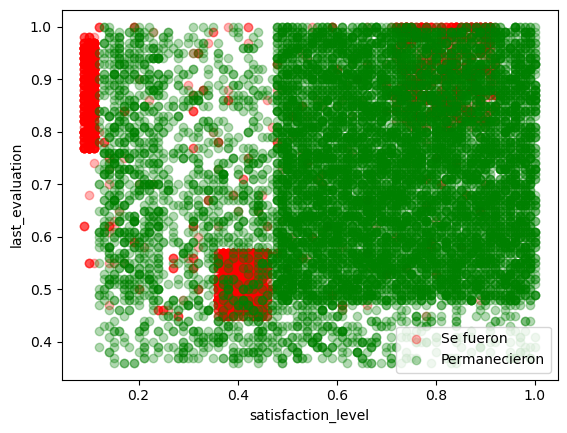

In [15]:
# Diagrama de dispersión
plt.scatter(S.satisfaction_level, S.last_evaluation,
            color="red", label="Se fueron", alpha=0.3)

plt.scatter(P.satisfaction_level, P.last_evaluation,
            color="green", label="Permanecieron", alpha=0.3)

plt.xlabel("satisfaction_level")
plt.ylabel("last_evaluation")
plt.legend()
plt.show()

In [17]:
y = data.left.values  # Extrae la variable objetivo
x_data = data.drop(["left"], axis=1)  # Separa las características de los datos
y

array([1, 1, 1, ..., 1, 1, 1], dtype=int64)

In [19]:
# Normalización
x = (x_data - np.min(x_data, axis=0)) / (np.max(x_data, axis=0) - np.min(x_data, axis=0))
x

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.318681,0.265625,0.0,0.285047,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.780220,0.781250,0.6,0.775701,0.500,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.021978,0.812500,1.0,0.822430,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.692308,0.796875,0.6,0.593458,0.375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.307692,0.250000,0.0,0.294393,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.340659,0.328125,0.0,0.257009,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
14995,0.307692,0.187500,0.0,0.299065,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
14996,0.307692,0.265625,0.0,0.219626,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
14997,0.021978,0.937500,0.8,0.859813,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [21]:
# Bases de entrenamiento y prueba
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, random_state=1
)

In [23]:
# Modelo KNN (K vecinos más cercanos)
from sklearn.neighbors import KNeighborsClassifier

In [25]:
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)
    prediction = knn.predict(x_test)

    print("K =", k, " Score:", knn.score(x_test, y_test))

K = 1  Score: 0.9617777777777777
K = 2  Score: 0.9577777777777777
K = 3  Score: 0.9453333333333334
K = 4  Score: 0.946
K = 5  Score: 0.9393333333333334
K = 6  Score: 0.9446666666666667
K = 7  Score: 0.9411111111111111
K = 8  Score: 0.9393333333333334
K = 9  Score: 0.9324444444444444
K = 10  Score: 0.934
K = 11  Score: 0.9293333333333333
K = 12  Score: 0.9311111111111111
K = 13  Score: 0.9262222222222222
K = 14  Score: 0.9288888888888889
K = 15  Score: 0.9253333333333333
K = 16  Score: 0.9264444444444444
K = 17  Score: 0.9228888888888889
K = 18  Score: 0.9211111111111111
K = 19  Score: 0.9186666666666666
K = 20  Score: 0.9188888888888889


In [27]:
# Modelo KNN (K vecinos más cercanos)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train, y_train)
prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test, y_test))

Score:  0.9617777777777777


In [29]:
y_pred = prediction
y_true = y_test

In [31]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
cm

array([[3296,  120],
       [  52, 1032]], dtype=int64)

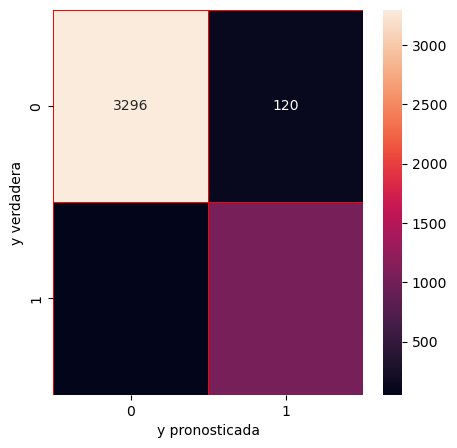

In [33]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize = (5,5))  # Configura el tamaño del gráfico

sns.heatmap(cm, annot = True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)  # Genera el mapa de calor
plt.xlabel("y pronosticada")
plt.ylabel("y verdadera")
plt.show()

In [35]:
# Cálculo precisión global
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]
PrecisionGlobal = Correctos / (Correctos + Incorrectos)
PrecisionGlobal

0.9617777777777777

In [37]:
PrecisionPermanecieron = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionPermanecieron

0.984468339307049

In [39]:
PrecisionSeFueron = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionSeFueron

0.8958333333333334

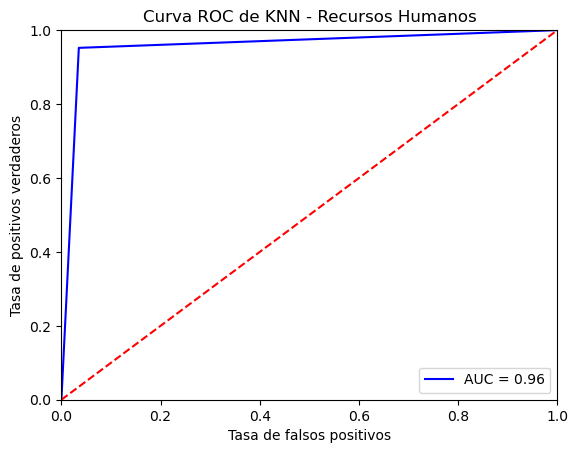

In [41]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_scores = knn.predict_proba(x_test)  # Obtiene las probabilidades de predicción

fpr, tpr, threshold = roc_curve(y_test, y_scores[:,1])  # Calcula las métricas para la curva
# fpr = False positive rate, tpr = True positive rate
roc_auc = auc(fpr, tpr)  # Calcula el área bajo la curva (AUC)

# Configuración y generación de la gráfica ROC
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = "lower right")
plt.plot([0,1], [0,1], 'r--')
plt.xlim([0,1])
plt.ylim([0,1])
plt.ylabel("Tasa de positivos verdaderos")
plt.xlabel("Tasa de falsos positivos")
plt.title("Curva ROC de KNN - Recursos Humanos")
plt.show()